<a href="https://colab.research.google.com/github/kdrhanegrilmez/mL-Notebooks/blob/main/pytorchAnn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
#library
import torch # pytorch kütüphaneleri
import torch.nn as nn ## yapay sinir ağı katmanlarını tanılamak için kullanılır
import torch.optim as optim #optimizasyon algoritmalarını içeren modül
import torchvision ## görüntü işleme ve pre -defined modelleri içerir
import torchvision.transforms as transforms # görüntü dönüşümlerini yapmak

import matplotlib.pyplot as plt #görselleştirme

In [2]:
#optional
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Kullanılan cihaz:",device)

Kullanılan cihaz: cuda


In [3]:
#veri setini yükleme - data loading
def get_data_loaders(batch_size = 64):
    # Her iterasyonda işlenecek veri miktarı
    transform = transforms.Compose([
        transforms.ToTensor(), # Görüntüyü tensörlere çevirir ve [0, 255] -> [0.0, 1.0] ölçeklendirir
        transforms.Normalize((0.5,), (0.5,)) # Piksel değerlerini -1 ile 1 arasına ölçeklendirir
    ])

    #MNIST veri setini indir ve eğitim - test kümelerini oluştur.
    train_test = torchvision.datasets.MNIST(root = "./data", train=True, download = True, transform = transform)
    test_set = torchvision.datasets.MNIST(root = "./data", train=False, download =True,transform=transform)

    #pytorch veri yükleyicisini oluşturuyorum.
    train_loader = torch.utils.data.DataLoader(train_test, batch_size=batch_size, shuffle=True)
    test_loader = torch.utils.data.DataLoader(test_set, batch_size=batch_size, shuffle=False)

    return train_loader, test_loader

train_loader, test_loader= get_data_loaders()

100%|██████████| 9.91M/9.91M [00:00<00:00, 12.9MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 357kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 3.24MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.03MB/s]


torch.Size([1, 28, 28])


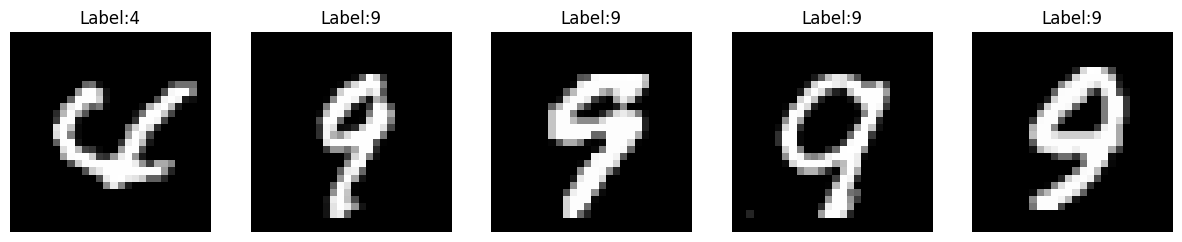

In [14]:
#data visualization

def visualize_samples(loader, num_samples=5):
  images, labels = next(iter(loader)) # ilk batch'ten görüntü ve etiketleri alalım.
  print(images[0].shape)
  fig, axes = plt.subplots(1, num_samples, figsize=(15, 3)) # num_samples kadar görselleştirme alanı

  # Eğer sadece 1 örnek istenir ve axes bir dizi olmazsa hata vermemesi için
  if num_samples == 1:
    axes = [axes]

  for i in range(num_samples):
    axes[i].imshow(images[i].squeeze(), cmap="gray") # görseli gri tonlamalı olarak göster
    axes[i].set_title(f"Label:{labels[i].item()}") # görüntüye ait sınıf etiketini başlık olarak yaz
    axes[i].axis("off") # eksenleri kapat
  plt.show()

visualize_samples(train_loader, 5)

In [15]:
# Define ANN model
#yapay sinir ağı class'ı oluşturalım.

class NeuralNetwork(nn.Module): #pytorch'un neural network sınıfından inharitance alıyor
  def __init__(self,):#Neural Network inşası için gerekli bileşenleri tanımla (self eklendi)
    super(NeuralNetwork,self).__init__()

    #elimizde bulunan görüntüleri vektör haline getireceğiz. 1D

    self.flatten = nn.Flatten() #elimizde bulunan görüntüleri (2D'den) vektör haline getirelim (1D'ye)

    #İlk Tam Bağlı Katmanı oluştur
    self.fc1 = nn.Linear(28*28,128) # İlk tam bağlı katman oluşturur. 28*28->784 input size, 128= output size

    #Aktivasyon Fonksiyonu Oluştur

    self.relu = nn.ReLU() #Aktivasyon fonskiyonu olarak ReLU kullandık.

    #İkinci Tam Bağlı Katmanı Oluştur

    self.fc2 = nn.Linear(128, 64) #İnput size =128, output size 64'e düşürdük.

    #Çıktı Katmanı oluştur
    self.fc3 = nn.Linear(64,10) #input size 64, output size=10, çünkü MNIST'de 10 farklı sınıf var 10 farklı sonuç elde edebilirim.



  def forward(self,x):# Forward Propagation: ileri yayılım, giriş olarak x aslın. x=görüntü

    #initial: x=28*28 lik bir görüntü -> düzleştir 784 halinde bir vektöre getir.
    x = self.flatten(x)
    #ilk bağlı katman
    x = self.fc1(x)
    #aktivasyon fonksiyonu
    x=self.relu(x)
    #ikinci bağlı katman
    x=self.fc2(x)
    x= self.relu(x)
    #output katmanı
    x=self.fc3(x)

    return x #modelimizin çıktısı

In [16]:
#create model and compile

model = NeuralNetwork().to(device) #to(device) ile çalıştıracak olan ekran kartını seçer

#kayıp fonskiyonu ve optimizasyon algoritmasını belirle

#Kayıp fonksiyonu -loss func. olarak Cross-Entropy Loss seçiyoruz, çok sınıflı sınıflandırma problemlerinde kullanıyoruz.
#Optimizer olarak Adam- Adaptive Momentum kullanacağız, ağırlıkları güncellemek için

define_loss_and_optimizer= lambda model:(
    nn.CrossEntropyLoss(),
    optim.Adam(model.parameters(),lr=0.001)
)



Epoch 1/10, Loss: 0.4037
Epoch 2/10, Loss: 0.1926
Epoch 3/10, Loss: 0.1418
Epoch 4/10, Loss: 0.1146
Epoch 5/10, Loss: 0.0981
Epoch 6/10, Loss: 0.0870
Epoch 7/10, Loss: 0.0765
Epoch 8/10, Loss: 0.0688
Epoch 9/10, Loss: 0.0626
Epoch 10/10, Loss: 0.0585


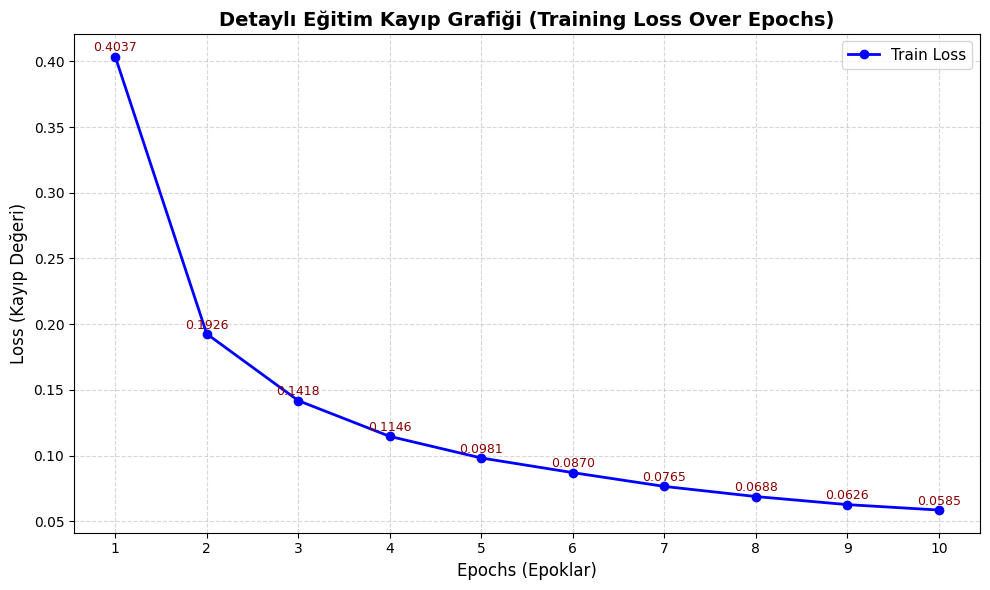

In [17]:
#train
def train_model(model, train_loader, criterion, optimizer, epochs=10):
    # modelimizi eğitim durumuna alalım
    model.train()

    # her bir epoch sonucunda elde edilen loss değerlerini saklamak için bir liste tanımlayacağız
    train_losses = []

    # belirtilen epoch sayısı kadar eğitimi tamamlamasına izin ver.
    for epoch in range(epochs):
        total_loss = 0 # toplam kayıp değeri

        # tüm eğitim verileri üzerinde belirli bir iterasyonu tamamla.
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device) # verileri cihaza taşı

            # gradyanları sıfırla
            optimizer.zero_grad()

            # modeli uygula (forward propagation)
            predictions = model(images)

            # loss hesapla -> y_pred ile y_real arasında
            loss = criterion(predictions, labels)

            # geri yayılım (gradyen hesaplama) (back propagation)
            loss.backward()

            # optimizer ile ağırlıkları güncelle
            optimizer.step()

            total_loss = total_loss + loss.item()

        avg_loss = total_loss / len(train_loader)
        train_losses.append(avg_loss)
        print(f"Epoch {epoch+1}/{epochs}, Loss: {avg_loss:.4f}")

    # Detaylandırılmış loss grafiği
    plt.figure(figsize=(10, 6))
    epochs_range = range(1, epochs + 1)
    plt.plot(epochs_range, train_losses, marker="o", linestyle="-", color="b", linewidth=2, label="Train Loss")

    # Her veri noktasının üzerine tam değerini yazdırma
    for i, val in enumerate(train_losses):
        plt.text(epochs_range[i], val + (max(train_losses)*0.01), f"{val:.4f}", ha="center", fontsize=9, color="darkred")

    plt.xlabel("Epochs (Epoklar)", fontsize=12)
    plt.ylabel("Loss (Kayıp Değeri)", fontsize=12)
    plt.title("Detaylı Eğitim Kayıp Grafiği (Training Loss Over Epochs)", fontsize=14, fontweight="bold")
    plt.xticks(epochs_range)
    plt.grid(True, which="both", linestyle="--", alpha=0.5) # Kılavuz çizgileri eklendi
    plt.legend(fontsize=11)
    plt.tight_layout()
    plt.show()

    return train_losses

# Modeli derleme fonksiyonundan loss ve optimizer alalım
criterion, optimizer = define_loss_and_optimizer(model)

# Eğitimi başlat
train_losses = train_model(model, train_loader, criterion, optimizer, epochs=10)

In [20]:
from numpy import size
#test

def test_model(model, test_loader):
  model.eval() #medeli değerlendirme moduna al
  correct = 0 #doğru tahmin sayacı
  total = 0 #toplam veri sayısı sayacı


  with torch.no_grad(): #gradyan hesaplama gereksiz olduğundan kapattık
    for images, labels in test_loader: #test veri kümesini döngüye al
      images, labels = images.to(device), labels.to(device)

      predictions = model(images)
      _, predicted = torch.max(predictions,1) #em yüksek olasılıklı sınıfın  etiketini bul
      #2 şey dönderiyor, birincisi ile ilgilenmediğimiz için "_" yapıyoruz

      total += labels.size(0) #toplam veri sayısını güncelle
      correct += (predicted == labels).sum().item() #doğru tahminleri say

  print(f"Test Accuracy: {100*correct/total:.3f}%")
test_model(model,test_loader)


Test Accuracy: 97.350%


torch.Size([1, 28, 28])


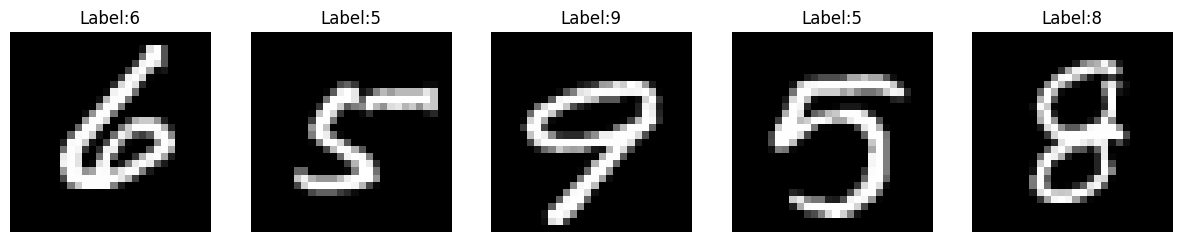

Epoch 1/10, Loss: 0.3816
Epoch 2/10, Loss: 0.1797
Epoch 3/10, Loss: 0.1299
Epoch 4/10, Loss: 0.1063
Epoch 5/10, Loss: 0.0899
Epoch 6/10, Loss: 0.0783
Epoch 7/10, Loss: 0.0722
Epoch 8/10, Loss: 0.0653
Epoch 9/10, Loss: 0.0585
Epoch 10/10, Loss: 0.0523


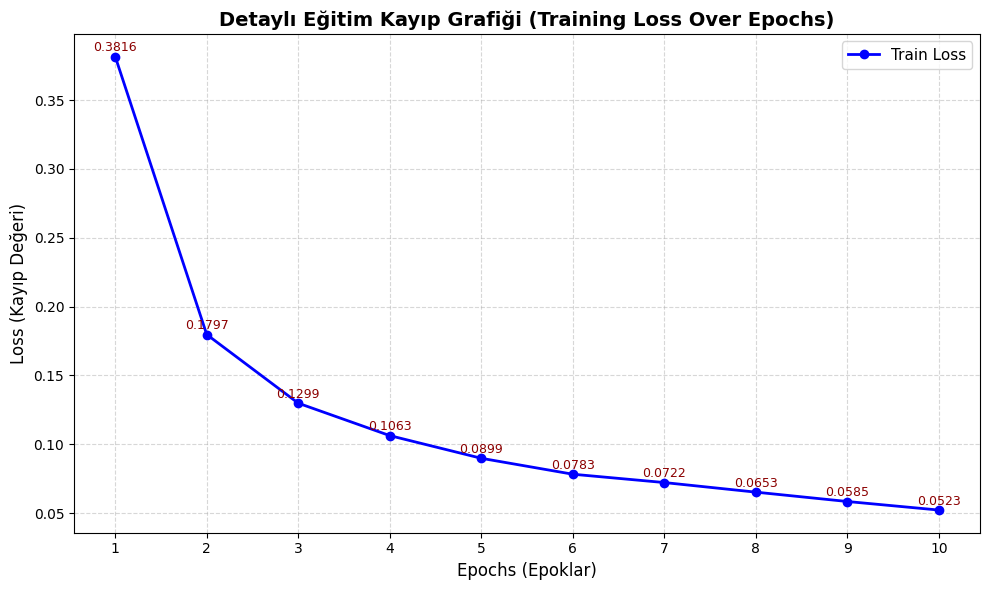

Test Accuracy: 97.310%


In [21]:
# main

if __name__ == "__main__":
  train_loader, test_loader = get_data_loaders() #veri yükleyicilerini al
  visualize_samples(train_loader, 5)
  model = NeuralNetwork().to(device)
  criterion, optimizer = define_loss_and_optimizer(model)
  train_model(model, train_loader, criterion, optimizer)
  test_model(model,test_loader)
